# **Project 30:** *Analyzis of Wordnet consistency in Synonymy and Antonymy relationships*
**Authors:**
* Miro Lammi (2208316), mlammi23@student.oulu.fi
* Eemeli Kyröläinen (2309218), ekyrolai23@student.oulu.fi

#### Requirements (recommended *Python 3.12*):
`pip install nltk` <br>
`pip install pandas` <br>
`pip install jupyter` <br>
`pip install matplotlib` <br>
`pip install numpy` <br>
`pip install gensim` <br>
`pip install scikit-learn` <br>
`pip install adjustText` <br>

or run: <br>
`pip install -r requirements.txt`

## Imports and initialization

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import gensim.downloader as api

from collections import defaultdict
from itertools import combinations
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from adjustText import adjust_text
from matplotlib.patches import Patch
from matplotlib.legend_handler import HandlerTuple

from nltk.corpus import wordnet as wn

POS_TAGS = [wn.NOUN, wn.VERB]
RELATIONS = {"synonym", "antonym"}
METHODS = ["path", "wup"]
COLORS = {
    ("synonym", wn.NOUN): "#4682B4",
    ("synonym", wn.VERB): "#8DB9D8",
    ("antonym", wn.NOUN): "#DC143C",
    ("antonym", wn.VERB): "#F08080",
}


def similarity(s1, s2, method="path"):
    if method == "path":
        return wn.synset(s1).path_similarity(wn.synset(s2))
    elif method == "wup":
        return wn.synset(s1).wup_similarity(wn.synset(s2))
    else:
        raise ValueError("[ERROR]: Invalid method! method must be one of {}".format(METHODS))

## 1. Getting synonyms and antonyms for each verb and noun in WordNet lexical database and calculating path similarity for each pair.

In [2]:
def get_all_pairs(pos):
    pairs = set()

    for synset in wn.all_synsets(pos):
        lemmas = synset.lemmas()

        for l1, l2 in combinations(lemmas, 2):
            w1, w2 = sorted([l1.name(), l2.name()])

            if w1 != w2:
                pairs.add((pos, "synonym", w1, w2, synset.name(), synset.name()))

        for lemma in lemmas:
            for antonym in lemma.antonyms():
                a_synset = antonym.synset()
                if a_synset.pos() != pos:
                    continue

                a, b = sorted([(lemma.name(), synset.name()),
                               (antonym.name(), a_synset.name())])

                if a[0] != b[0]:
                    pairs.add((pos, "antonym", a[0], b[0], a[1], b[1]))
    return pairs

results = []

for pos in POS_TAGS:
    pairs = get_all_pairs(pos)

    for p, rel, w1, w2, s1, s2 in pairs:
        sim = similarity(s1, s2, "wup")
        results.append({
            'pos': p,
            'relation': rel,
            'word1': w1,
            'word2': w2,
            's1': s1,
            's2': s2,
            'similarity': sim
        })

DATAFRAME = pd.DataFrame(results)

statistics = (DATAFRAME.groupby(["pos", "relation"])["similarity"].agg(["count", "min", "max", "mean"]))
display(statistics)

count       min       max      mean
pos relation                                      
n   antonym     1076  0.125000  0.933333  0.752211
    synonym   107469  0.727273  1.000000  0.996726
v   antonym      548  0.111111  0.857143  0.367114
    synonym    24577  0.666667  1.000000  0.999938

Wu-Palmer similarity separates the two relations clearly in this table. Synonym pairs have a mean similarity of about 0.997 for nouns and 0.9999 for verbs, with minima of 0.73 and 0.67. Antonym pairs are much lower and more spread out. The noun antonyms have a mean of 0.75 (range 0.125 to 0.933) and verb antonyms a mean of 0.37 (range 0.111 to 0.857).

Synonym similarity is close to 1 by construction. WordNet synonyms are lemmas of the same synset, so we compare a synset with itself, and Wu-Palmer of a synset with itself is 1. The values slightly below 1 are most likely edge cases in NLTK’s implementation. The synonym row therefore mostly shows the measure behaving as expected rather than saying something new about synonymy. The antonym row is the informative one.

Noun antonyms (mean 0.75) tend to be contrasting members of the same category, such as man/woman or hot/cold concepts, and sit close together in the hierarchy. Verb antonyms are much lower (0.37). A plausible explanation is that the verb hierarchy is shallow and split into many separate trees, so opposites often end up far apart, though this is something to check rather than something our output shows. Note that the code uses wup, and that there are about 100× more synonym pairs than antonym pairs (107,469 vs 1,076 for nouns; 24,577 vs 548 for verbs).

 ## 2. Generate pair similarity distribution histograms

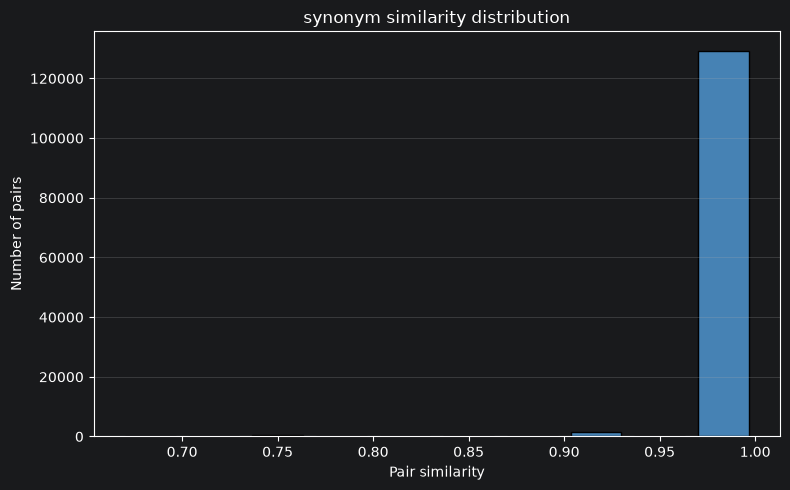

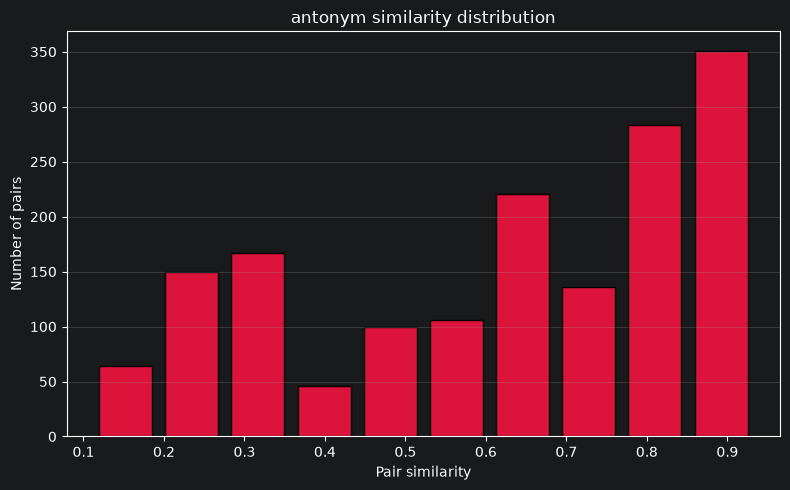

In [3]:
BIN_COUNT = 10

for relation in RELATIONS:
    sims = DATAFRAME.loc[DATAFRAME["relation"] == relation, "similarity"].dropna()

    min_sim = sims.min()
    max_sim = sims.max()

    bins = np.linspace(min_sim, max_sim, BIN_COUNT + 1)

    plt.figure(figsize=(8,5))
    plt.hist(sims, bins=bins, edgecolor="black", rwidth=0.8, color=COLORS[relation, "n"])
    plt.xlabel("Pair similarity")
    plt.ylabel("Number of pairs")
    plt.title(f"{relation} similarity distribution")
    plt.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.show()
    print()

The synonym histogram is extremely concentrated. The range runs from about 0.67 to 1.0, but nearly all of the ~130,000 pairs fall in the last bin above 0.95, so the other bins are barely visible. This matches the near-1 mean from section 1 and confirms that synonym similarity is almost degenerate.

The antonym histogram is spread over the whole range (about 0.11 to 0.93) and looks bimodal. There is a lower group around 0.2 to 0.35 and a larger group rising toward 0.8 to 0.93, with the largest bin at the top. This fits the section 1 statistics, where noun antonyms average 0.75 and verb antonyms 0.37, so the two modes probably come from the two parts of speech. The histograms pool nouns and verbs, so plotting them per POS would show this directly.

The two distributions overlap only at the top end of the antonym range. Many antonym pairs, the high-similarity ones, mostly nouns still reach 0.8 to 0.93 and could be confused with synonyms by a similarity threshold.

 ## 3. Difference between semantic similarity can be used distinguish between synonymy and antonymy
"Validating your answer using statistical hypothesis testing"

In [4]:
# Reserved for possible code for 3.
pass

## 4. Transitivity relationships in synonyms and antonyms

,pos,relation,total,successful,percentage
0,n,synonym,367083,257613,70.178407
1,n,antonym,67,20,29.850746
2,v,synonym,233414,110223,47.222103
3,v,antonym,91,21,23.076923


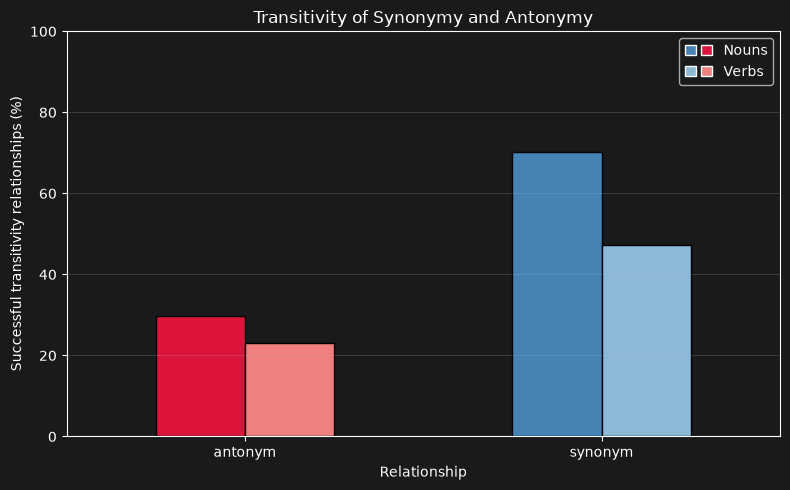

In [5]:
def build_relations_tables(df_pos):
    synonyms = defaultdict(set)
    antonyms = defaultdict(set)

    for row in df_pos.itertuples(index=False):
        table = synonyms if row.relation == "synonym" else antonyms
        table[row.word1].add(row.word2)
        table[row.word2].add(row.word1)

    return synonyms, antonyms


def get_transitivity_relationships(relations, synonyms):
    count = 0
    success = 0

    for y, neighbor in relations.items():
        for x, z in combinations(neighbor, 2):
            count += 1
            if z in synonyms.get(x, set()):
                success += 1

    return count, success


results = []

for pos in POS_TAGS:
    df_pos = DATAFRAME[DATAFRAME["pos"] == pos]

    synonyms, antonyms = build_relations_tables(df_pos)

    for relation, relations in [("synonym", synonyms), ("antonym", antonyms)]:
        total, successful = get_transitivity_relationships(relations, synonyms)

        results.append({
            'pos': pos,
            'relation': relation,
            'total': total,
            'successful': successful,
            'percentage': (successful / total) * 100 if total > 0 else 0
        })

df_transitivity = pd.DataFrame(results)
display(df_transitivity.groupby(["pos", "relation"]))

pivot = df_transitivity.pivot(
    index="relation",
    columns="pos",
    values="percentage"
)

ax = pivot.plot.bar(figsize=(8,5), edgecolor="black", rot=0)
for container, pos in zip(ax.containers, pivot.columns):
    for bar, relation in zip(container, pivot.index):
        bar.set_facecolor(COLORS[(relation, pos)])

ax.set_title("Transitivity of Synonymy and Antonymy")
ax.set_xlabel("Relationship")
ax.set_ylabel("Successful transitivity relationships (%)")
ax.set_ylim(0, 100)
ax.legend(["Nouns", "Verbs"])
legend_handles = [
    (
        Patch(facecolor=COLORS[('synonym', 'n')], edgecolor="white"),
        Patch(facecolor=COLORS[('antonym', 'n')], edgecolor="white")
    ),
    (
        Patch(facecolor=COLORS[('synonym', 'v')], edgecolor="white"),
        Patch(facecolor=COLORS[('antonym', 'v')], edgecolor="white")
    )
]

ax.legend(
    legend_handles,
    ["Nouns", "Verbs"],
    handler_map={tuple: HandlerTuple(ndivide=None)}
)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Transitivity does not hold reliably in WordNet when we work at the word level. Only 70.2% of noun synonym triples (X~Y, Y~Z, with X and Z checked) and 47.2% of verb triples satisfy X~Z.

Within a single synset, synonymy is transitive by definition, since a synset is a set of mutually interchangeable lemmas. So the failures almost certainly come from polysemy. Our tables are keyed on words and not on senses, so X~Y can come from one sense of Y and Y~Z from another, and X and Z then have nothing to do with each other. Verbs are more polysemous than nouns in WordNet, which is a likely reason for their much lower rate (47% vs 70%). Highly polysemous hub words also generate very many triples, so they dominate the totals (367,083 noun and 233,414 verb triples). Redoing the test at the sense (synset) level should give values near 100%, and this would be a useful check.

For antonyms, the rule “antonym of an antonym is a synonym” holds in only 29.9% of noun cases (20 of 67) and 23.1% of verb cases (21 of 91). It is not a reasonable general rule, because two words that share an antonym are often similar in meaning without being listed as synonyms. The antonym samples are small, so these percentages are noisy. Overall, neither relation is strongly transitive in WordNet, and antonymy is much less so.

## 5. Hypernymy in synonyms

,pos,total,shared hypernym count,percentage
0,Noun,105032,92926,88.473989
1,Verb,23020,21646,94.031277


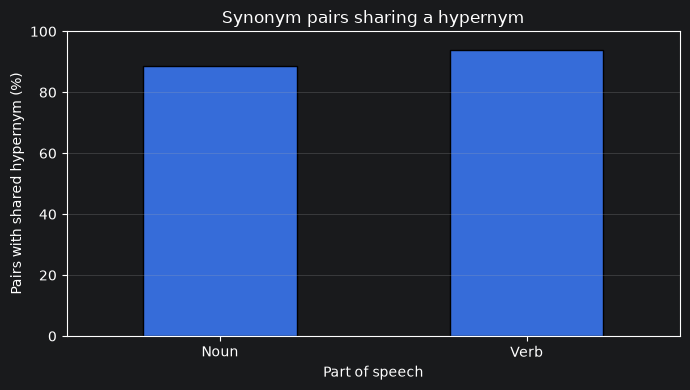

In [6]:
def has_common_hypernym(word1, word2, pos):
    for s1 in wn.synsets(word1, pos=pos):
        for s2 in wn.synsets(word2, pos=pos):
            if set(s1.hypernyms()) & set(s2.hypernyms()):
                return True
    return False


results = []

for pos in POS_TAGS:
    df_synonyms = DATAFRAME[
        (DATAFRAME["pos"] == pos) &
        (DATAFRAME["relation"] == "synonym")
    ]

    df_synonyms = df_synonyms.drop_duplicates(subset=["word1", "word2"])
    total = len(df_synonyms)

    hypernym_count = sum(
        has_common_hypernym(row.word1, row.word2, pos) for row in df_synonyms.itertuples(index=False)
    )

    results.append({
        'pos': "Noun" if pos == wn.NOUN else "Verb",
        'total': total,
        'shared hypernym count': hypernym_count,
        'percentage': (hypernym_count / total) * 100 if total > 0 else 0
    })

df_hypernyms_syn = pd.DataFrame(results)
display(df_hypernyms_syn)

ax = df_hypernyms_syn.plot.bar(
    x="pos",
    y="percentage",
    figsize=(7, 4),
    legend=False,
    edgecolor="black",
    rot=0
)

ax.set_title("Synonym pairs sharing a hypernym")
ax.set_xlabel("Part of speech")
ax.set_ylabel("Pairs with shared hypernym (%)")
ax.set_ylim(0, 100)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

88.5% of noun synonym pairs and 94.0% of verb synonym pairs have at least one sense combination with a common direct hypernym. The intuition that synonyms share a parent category is therefore largely supported. After dropping duplicate word pairs, the totals are 105,032 nouns and 23,020 verbs.

This result should be read with two caveats. First, synonym pairs come from the same synset, so they trivially share hypernyms whenever that synset has any. The failing cases are therefore not pairs that really have different parents. They more likely come from synsets with no hypernyms() entry: for nouns, probably instance synsets (e.g. named entities), which use instance_hypernyms() instead, and for verbs, the many top-level verb synsets. We have not verified this, but checking instance_hypernyms() and counting hypernym-less synsets would show it quickly. Second, the test is existential over all senses of both words and only looks at the direct parent. It is lenient on the first point and strict on the second, so the numbers are not very precise.

## 6. Hypernymy in antonyms

,pos,total,shared hypernym count,percentage
0,Noun,992,597,60.181452
1,Verb,476,164,34.453782


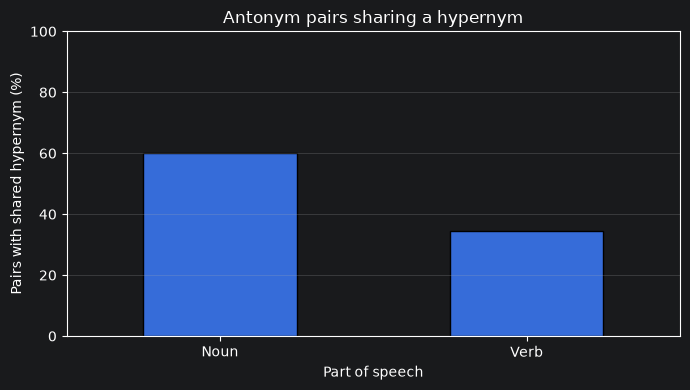

In [7]:
results = []

for pos in POS_TAGS:
    df_antonyms = DATAFRAME[
        (DATAFRAME["pos"] == pos) &
        (DATAFRAME["relation"] == "antonym")
    ]

    df_antonyms = df_antonyms.drop_duplicates(subset=["word1", "word2"])
    total = len(df_antonyms)

    hypernym_count = sum(
        has_common_hypernym(row.word1, row.word2, pos) for row in df_antonyms.itertuples(index=False)
    )

    results.append({
        'pos': "Noun" if pos == wn.NOUN else "Verb",
        'total': total,
        'shared hypernym count': hypernym_count,
        'percentage': (hypernym_count / total) * 100 if total > 0 else 0
    })

df_hypernyms_ant = pd.DataFrame(results)
display(df_hypernyms_ant)

ax = df_hypernyms_ant.plot.bar(
    x="pos",
    y="percentage",
    figsize=(7, 4),
    legend=False,
    edgecolor="black",
    rot=0
)

ax.set_title("Antonym pairs sharing a hypernym")
ax.set_xlabel("Part of speech")
ax.set_ylabel("Pairs with shared hypernym (%)")
ax.set_ylim(0, 100)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Antonyms share a direct hypernym much less often than synonyms: 60.2% of noun pairs (597 of 992) and 34.5% of verb pairs (164 of 476). The gap from synonyms is about 28 points for nouns (88.5% vs 60.2%) and about 60 points for verbs (94.0% vs 34.5%).

For nouns, a majority share a parent, which fits the view that antonyms are contrasting members of one category (opposite ends of the same dimension). This is consistent with their high Wu-Palmer similarity in section 1 (mean 0.75). For verbs, only about a third share a parent, which is in line with their low similarity (mean 0.37). Verb opposites such as rise/fall or buy/sell are often placed in different parts of a flat, fragmented hierarchy. As in section 5, the test uses any sense combination of the two words and not the specific antonym synsets, which probably overestimates the share, and it only checks the direct parent.

Taken together with section 1, the shared-hypernym test separates synonyms from antonyms more sharply for verbs than for nouns. For nouns, antonyms stay close to synonyms both in similarity and in structure.

## 7. Word2Vec minimum and maximum distance

,pos,relation,extreme,word1,word2,distance_2d
0,n,synonym,min,Klan,Ku_Klux_Klan,0.001558
1,n,synonym,max,Elvis,dose,167.219849


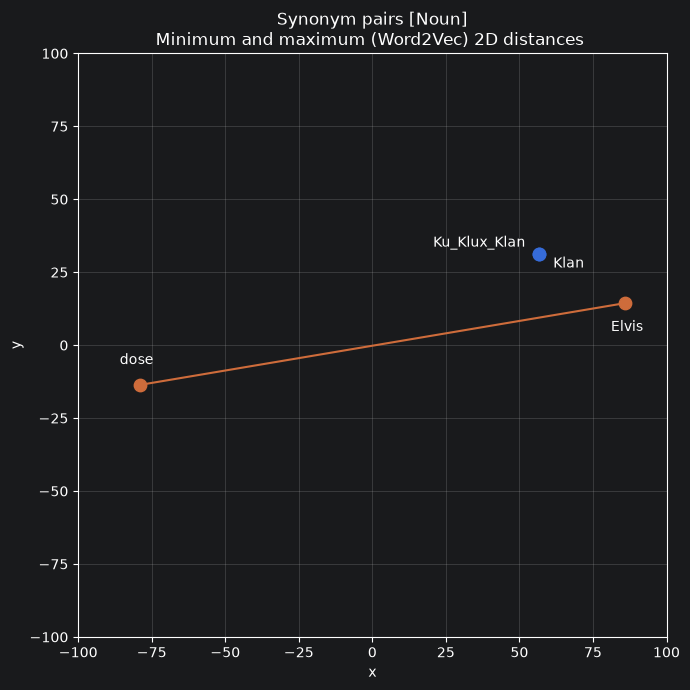

,pos,relation,extreme,word1,word2,distance_2d
2,n,antonym,min,leeward,windward,0.006105
3,n,antonym,max,immortality,mortality,133.780746


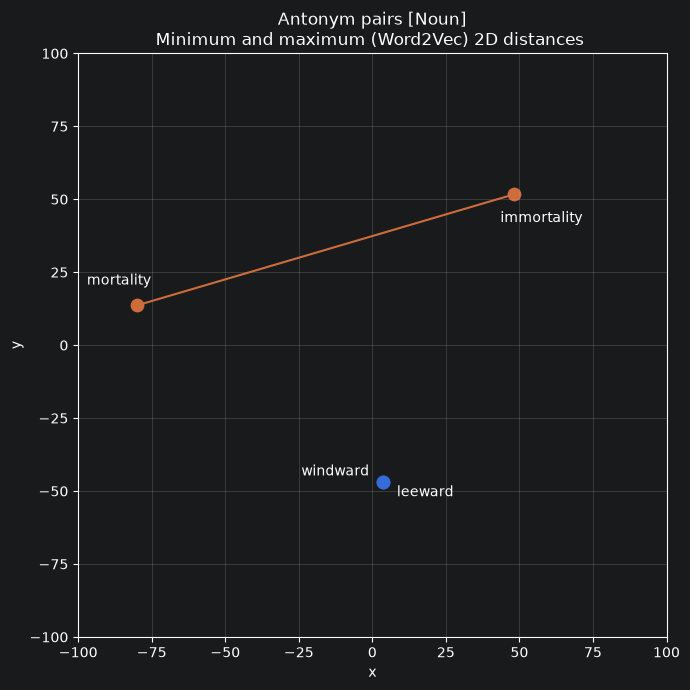

,pos,relation,extreme,word1,word2,distance_2d
4,v,synonym,min,chaperon,chaperone,0.002884
5,v,synonym,max,befool,gull,162.248825


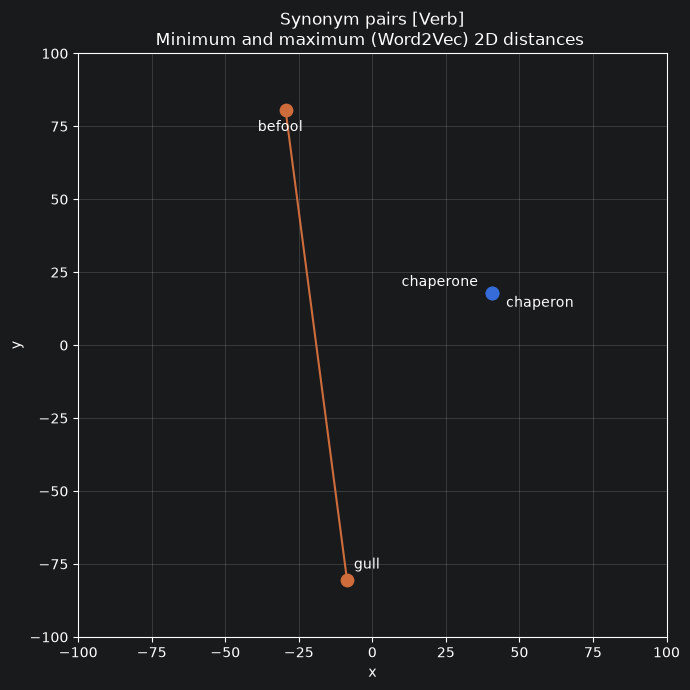

,pos,relation,extreme,word1,word2,distance_2d
6,v,antonym,min,emigrate,immigrate,0.001238
7,v,antonym,max,dislodge,lodge,119.190750


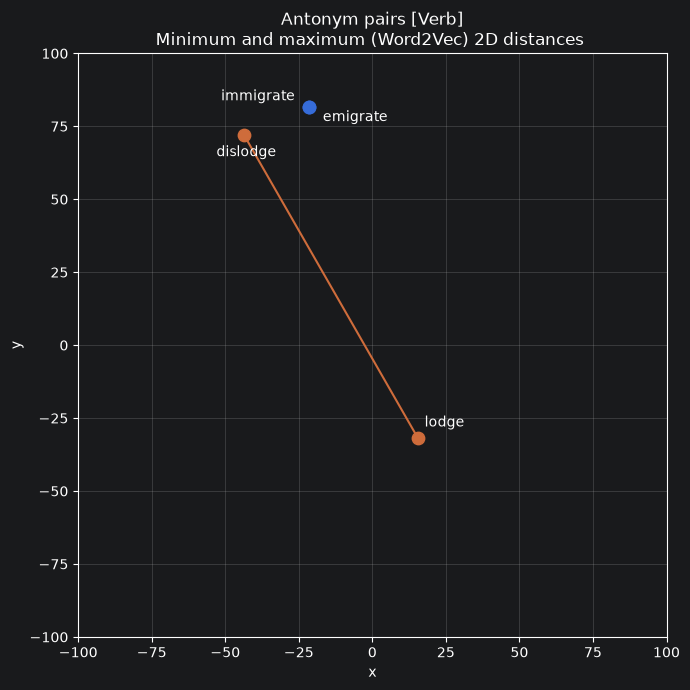

In [56]:
word2vec = api.load("word2vec-google-news-300")

all_words = pd.unique(DATAFRAME[["word1", "word2"]].to_numpy().ravel())

def find_matching_w2v_word(word):
    candidates = [
        word,
        word.lower(),
        word.replace("_", " "),
        word.lower().replace("_", " "),
        word.title()
    ]

    for candidate in candidates:
        if candidate in word2vec:
            return candidate
    return None


word_mapping = {
    word: find_matching_w2v_word(word) for word in all_words
}

valid_w2v_words = {
    word: mapped for word, mapped in word_mapping.items() if mapped is not None
}

print("Total unique words:", len(all_words))
print("Matching words found in Word2Vec:", len(valid_w2v_words))
print(f"Coverage: {len(valid_w2v_words) / len(all_words) * 100:.2f}%")

embedding_words = list(dict.fromkeys(valid_w2v_words.values()))

X = np.array(
    [word2vec[word] for word in embedding_words],
    dtype=np.float32
)

# reduce dimensions from original X from (N,300) to (N,50)
PCA_reduced_X = PCA(
    n_components=min(50, X.shape[0], X.shape[1]),
    random_state=2026
).fit_transform(X)

# project PCA reduced X from (N,50) into 2D
X_2d_projection = TSNE(
    n_components=2,
    perplexity=min(30, X.shape[0] - 1),
    random_state=2026,
    init="pca",
    learning_rate="auto"
).fit_transform(PCA_reduced_X)

word_coordinates_2d = dict(zip(embedding_words, X_2d_projection))

def distance_2d(w1, w2):
    if w1 not in word_coordinates_2d or w2 not in word_coordinates_2d:
        return np.nan
    return np.linalg.norm(word_coordinates_2d[w1] - word_coordinates_2d[w2])


DATAFRAME["distance_2d"] = [distance_2d(w1, w2) for w1, w2 in zip(DATAFRAME["word1"], DATAFRAME["word2"])]


df_unique_pairs = (
    DATAFRAME.dropna(subset=["distance_2d"])
    .drop_duplicates(subset=["pos", "relation", "word1", "word2"]).copy()
)

minmax_2d_dists = []

for pos in POS_TAGS:
    for relation in RELATIONS:
        group = df_unique_pairs[
            (df_unique_pairs["relation"] == relation) & (df_unique_pairs["pos"] == pos)
        ]
        min_row = group.loc[[group["distance_2d"].idxmin()]].iloc[0]
        max_row = group.loc[[group["distance_2d"].idxmax()]].iloc[0]
        minmax_2d_dists.append({
            'pos': pos,
            'relation': relation,
            "extreme": "min",
            'word1': min_row["word1"],
            'word2': min_row["word2"],
            'distance_2d': min_row["distance_2d"]
        })
        minmax_2d_dists.append({
            'pos': pos,
            'relation': relation,
            "extreme": "max",
            'word1': max_row["word1"],
            'word2': max_row["word2"],
            'distance_2d': max_row["distance_2d"]
        })

df_minmax_2d_dists = pd.DataFrame(minmax_2d_dists)


# Everything below this is just for displaying the results
# ---
def plot_min_max_for_group(df_group, coords, pos, relation):
    min_row = df_group.loc[df_group["distance_2d"].idxmin()]
    max_row = df_group.loc[df_group["distance_2d"].idxmax()]
    isMax = False
    plt.figure(figsize=(7, 7))

    for row in [min_row, max_row]:
        w1 = row["word1"]
        w2 = row["word2"]
        x1, y1 = coords[w1]
        x2, y2 = coords[w2]
        xytexts = [(10, -10), (-10, 5)]
        ha = ["left", "right"]

        plt.scatter([x1, x2], [y1, y2], s=80)
        plt.plot([x1, x2], [y1, y2], linewidth=1.5)

        if isMax and row["pos"] == wn.NOUN:
            xytexts = [(-10, -20), (10, 15)]

        if isMax and row["pos"] == wn.VERB:
            xytexts = [(-20, -15), (5, 8)]
            ha = ["left", "left"]

        plt.annotate(
            w1, (x1, y1),
            xytext=xytexts[0],
            textcoords="offset points",
            ha=ha[0],
            fontsize=10
        )
        plt.annotate(
            w2, (x2, y2),
            xytext=xytexts[1],
            textcoords="offset points",
            ha=ha[1],
            fontsize=10
        )
        isMax = True

    title_pos = "Noun" if pos == "n" else "Verb"
    plt.title(f"{relation.capitalize()} pairs [{title_pos}]\nMinimum and maximum (Word2Vec) 2D distances ")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.xlim(-100, 100)
    plt.ylim(-100, 100)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

for pos in ["n", "v"]:
    for relation in ["synonym", "antonym"]:
        group = df_minmax_2d_dists[
            (df_minmax_2d_dists["pos"] == pos) &
            (df_minmax_2d_dists["relation"] == relation)
        ]
        display(group)
        if not group.empty:
            plot_min_max_for_group(group, word_coordinates_2d, pos, relation)

[Interpretation of results]

## 8. Synonymy and antonymy analysis outside WordNet Lexicon database